In [1]:
%%time
#%load_ext autoreload
#%autoreload 2

CPU times: total: 0 ns
Wall time: 16.7 μs


# Imports

In [2]:
%%time
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
import skeliner as sk
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from scipy import ndimage
import re

CPU times: total: 1.19 s
Wall time: 3.84 s


In [3]:
%%time
import os
import sys

sys.path.append("../utils")

CPU times: total: 0 ns
Wall time: 35.5 μs


In [4]:
%%time
import data_2p_loader as data_loader
import data_io
import rf
from plot import plot_scale_bar
from style import set_rc_params

CPU times: total: 93.8 ms
Wall time: 245 ms


# Data

In [5]:
%%time
config = data_io.get_data_config()
data_2p_dir = config["data_2p_dir"]
skel_dir = config["skel_dir"]
for f in (config["mc_rf_file"], config["em_2p_registration_file"], config["rf_alignment_file"]):
    assert os.path.isfile(os.path.join(data_2p_dir, f)), f"{f} not found in {data_2p_dir}"

chirp_file = os.path.join(config["data_2p_dir"], "stimuli", "global_chirp", "chirp_stimulus.npy")
chirp_stimulus = np.load(chirp_file)
assert os.path.isfile(chirp_file), chirp_file
assert os.path.isdir(skel_dir), skel_dir
df_rois = data_loader.load_df_rois()
df = data_loader.load_df_rois_morph(df_rois=df_rois)
print(f"{len(df)} ROIs mapped to a proofread EM cell")

376 ROIs mapped to a proofread EM cell
CPU times: total: 3.64 s
Wall time: 6.53 s


## Selected cell types

Resource-paper labels (`data_2p_loader` applies the RGC types sheet). The RGC types were renamed: EW5ti was UHD, ON
sustained alpha was ON alpha and ON DS EW7i was ON DS sustained - direction unknown.

In [6]:
CELL_TYPES = [
    "Midnight",                      # dAC
    "EW5ti",                         # RGC
    "Separate dendrites and axons",  # dAC
    "ON sustained alpha",            # RGC
    "ON DS EW7i",                    # RGC
]

df_sel = df[df["Cell Type"].isin(CELL_TYPES)].copy()
cell_types = df_sel["Cell Type"].value_counts().reindex(CELL_TYPES)  # ROIs per type, in the order above
assert cell_types.notna().all(), f"cell type(s) not found: {cell_types[cell_types.isna()].index.tolist()}"
df_sel["swc_path"] = [os.path.join(skel_dir, f"{int(seg_id)}.swc") for seg_id in df_sel["Latest SegID"]]

missing = df_sel.loc[~df_sel["swc_path"].map(os.path.isfile), "Latest SegID"].tolist()
assert not missing, f"{len(missing)} skeleton(s) not in {skel_dir}, unpack swc-2p.zip there: {missing}"
df_sel["skel"] = df_sel["swc_path"].map(sk.io.load_swc)

print(f"{len(cell_types)} cell types, {len(df_sel)} ROIs")

5 cell types, 53 ROIs


Number of ROIs per field, and their spread along the ventral-dorsal axis (max - min position, µm):

In [7]:
per_field = df_sel.groupby(["Cell Type", "field"])["ventral_dorsal_pos_um"].agg(
    n="size", vd_range_um=lambda pos: pos.max() - pos.min())
table = per_field.unstack("field").reindex(cell_types.index)
table.insert(0, ("n", "total"), cell_types)
table.round(1)

n                          vd_range_um        \
field                        total GCL0 GCL1 GCL2 GCL3 GCL4        GCL0  GCL1   
Cell Type                                                                       
Midnight                         5  2.0  1.0  NaN  1.0  1.0        46.3   0.0   
EW5ti                           15  4.0  4.0  3.0  2.0  2.0        45.9  66.9   
Separate dendrites and axons    18  3.0  6.0  3.0  4.0  2.0        34.2  58.0   
ON sustained alpha               5  1.0  1.0  2.0  NaN  1.0         0.0   0.0   
ON DS EW7i                      10  2.0  1.0  2.0  3.0  2.0        17.5   0.0   

                                                
field                         GCL2  GCL3  GCL4  
Cell Type                                       
Midnight                       NaN   0.0   0.0  
EW5ti                         25.4  68.6  29.4  
Separate dendrites and axons  63.5  42.5  30.7  
ON sustained alpha            67.1   NaN   0.0  
ON DS EW7i                    25.0  60.9  13.3

# Plot

In [8]:
set_rc_params()
mpl.rcParams["svg.fonttype"] = "none"  # keep text editable in the svg

fig_dir = "../figures/calcium_data/RGC_light_adaptation"
os.makedirs(fig_dir, exist_ok=True)

One figure per cell type, one column per field with cells of this type:

- skeletons: x-y projection of the EM coordinates, 343 µm wide and centered on the mean soma position, one color per
  cell, 50 µm scale bar
- chirp: stimulus, and the normalized responses (`chirp_average_norm`, 4x downsampled in time), one row per ROI
- moving bar: time component of the responses (`bar_time_component`), one row per ROI

Each heatmap has as many rows as the field with the most ROIs of this cell type: that field fills its heatmap, and
a row has the same height in all fields of a figure (but not across cell types). The vertical scale bar shows 1, 2, 5
or 10 ROIs, at most half of the heatmap height. The dashed lines mark the same time points as in the response
overview (`plot_response_overview.ipynb`).

In [9]:
tab20 = plt.get_cmap("tab20")


def downsample_uniform_filter(data, n):
    """Downsample along time (axis 1) by averaging over n samples."""
    filtered = ndimage.uniform_filter1d(data, size=n, axis=1)
    return filtered[:, ::n]


def plot_skel_thin(ax, skel, soma_color, dendrite_color, lw=0.4, alpha=0.9, soma_size=20):
    """Plot a skeleton's edges as thin lines (no radius) plus a soma marker."""
    segments = skel.nodes[:, :2][skel.edges]
    ax.add_collection(LineCollection(segments, colors=dendrite_color, linewidths=lw, alpha=alpha, zorder=2,
                                     rasterized=True))
    ax.scatter(*skel.soma.center[:2], s=soma_size, color=soma_color, edgecolors="none", zorder=5, rasterized=True)

In [10]:
def plot_cell_type(df, cell_type, chirp_stimulus, cmap="coolwarm", size_full_um=343):
    """Skeletons, chirp and moving-bar responses of one cell type, one column per field."""
    df_cell = df[df["Cell Type"] == cell_type]
    fields = sorted(df_cell["field"].dropna().unique())
    n_fields = len(fields)

    # heatmap rows: the largest number of ROIs in one field; scale bar: 1, 2, 5 or 10 ROIs, at most half of that
    nmax = df_cell["field"].value_counts().max()
    n_scale = max([n for n in (1, 2, 5, 10) if n <= nmax / 2], default=1)
    scale_label = f"{n_scale} ROI" + ("s" if n_scale > 1 else "")

    fig, axs = plt.subplots(3, n_fields, figsize=(1.4 * n_fields, 3), height_ratios=(2, 1, 1), squeeze=False)
    for col in range(1, n_fields):
        axs[1, col].sharey(axs[1, 0])
        axs[2, col].sharey(axs[2, 0])
    for ax in axs.flat:
        ax.axis("off")
    plt.tight_layout(h_pad=0)

    for i, field in enumerate(fields):
        df_field = df_cell[df_cell["field"] == field]

        # skeletons
        ax = axs[0, i]
        skels = list(df_field["skel"])
        field_center = np.mean([skel.soma.center[:2] for skel in skels], axis=0)
        for j, skel in enumerate(skels):
            plot_skel_thin(ax, skel, soma_color=tab20(2 * (j % 10)), dendrite_color=tab20(2 * (j % 10) + 1))

        ax.set_xlim(field_center[0] - size_full_um / 2, field_center[0] + size_full_um / 2)
        ax.set_ylim(field_center[1] - size_full_um / 2, field_center[1] + size_full_um / 2)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.text(0, 1, field.replace("GCL", "F"), fontsize=14, ha="left", va="top", transform=ax.transAxes)
        ax.plot([0, 50 / size_full_um], [0.1, 0.1], c="k", solid_capstyle="butt", lw=2, clip_on=False,
                transform=ax.transAxes)
        if i == 0:
            ax.text(0, 0.1, "50 µm", c="k", ha="left", va="bottom", fontsize=14, transform=ax.transAxes)

        t_chirp = np.arange(df_field["chirp_average_norm"].iloc[0].size) * df_field["chirp_average_dt"].iloc[0]
        t_bar = np.arange(df_field["bar_time_component"].iloc[0].size) * df_field["bar_snippets_dt"].iloc[0]

        # chirp: stimulus on top, one row per ROI
        chirps = np.vstack(df_field["chirp_average_norm"])
        n_chirp = len(chirps)
        im_chirps = np.full((nmax, chirps.shape[1]), np.nan)
        im_chirps[:n_chirp] = chirps
        im_chirps = downsample_uniform_filter(im_chirps, n=4)

        ax = axs[1, i]
        ax.plot(np.linspace(t_chirp[0], t_chirp[-1], len(chirp_stimulus)),
                1.1 + 0.1 * chirp_stimulus / np.max(chirp_stimulus),
                c="k", clip_on=False, lw=1, solid_capstyle="butt")
        ax.imshow(im_chirps, vmin=-1, vmax=1, aspect="auto", extent=(t_chirp[0], t_chirp[-1], 0, 1), cmap=cmap,
                  interpolation="none")
        ax.set_xlim(t_chirp[0], t_chirp[-1])
        for t in [2, 5, 8, 10, 20.5, 30]:
            ax.plot([t, t], [1 - n_chirp / nmax, 1], c="k", lw=0.8, ls="--")
        if i == 0:  # scale bars: 2 s, n_scale ROIs
            ax.plot([0, 2], [-0.1, -0.1], c="k", solid_capstyle="butt", lw=2, clip_on=False)
            ax.plot([-0.05 * t_chirp[-1]] * 2, [0, n_scale / nmax], c="k", solid_capstyle="butt", lw=2,
                    clip_on=False)

        # moving bar: one row per ROI
        bars = np.vstack(df_field["bar_time_component"])
        n_bar = len(bars)
        im_bars = np.full((nmax, bars.shape[1]), np.nan)
        im_bars[:n_bar] = bars

        ax = axs[2, i]
        # invisible line at the height of the chirp stimulus, so that both heatmap rows get the same y-limits
        ax.plot([t_bar[0], t_bar[-1]], 1.1 + 0.1 * np.array([0, 1]), c=(1, 1, 1, 0), clip_on=False, lw=1,
                solid_capstyle="butt")
        ax.imshow(im_bars, vmin=-1, vmax=1, aspect="auto", extent=(t_bar[0], t_bar[-1], 0, 1), cmap=cmap,
                  interpolation="none")
        ax.set_xlim(t_bar[0], t_bar[-1])
        for t in [1.152, 2.432]:
            ax.plot([t, t], [1 - n_bar / nmax, 1], c="k", lw=0.8, ls="--")
        if i == 0:  # scale bars: 2 s, n_scale ROIs
            ax.plot([0, 2], [-0.1, -0.1], c="k", solid_capstyle="butt", lw=2, clip_on=False)
            ax.text(0, -0.2, "2 s", c="k", ha="left", va="top", fontsize=14)
            ax.plot([-0.05 * t_bar[-1]] * 2, [0, n_scale / nmax], c="k", solid_capstyle="butt", lw=2,
                    clip_on=False)
            ax.text(-0.05 * t_bar[-1], 0, scale_label, c="k", ha="right", rotation=90, va="bottom", fontsize=14)
            fig.suptitle(f"{cell_type}", y=1.02, fontsize=12)

    return fig, axs

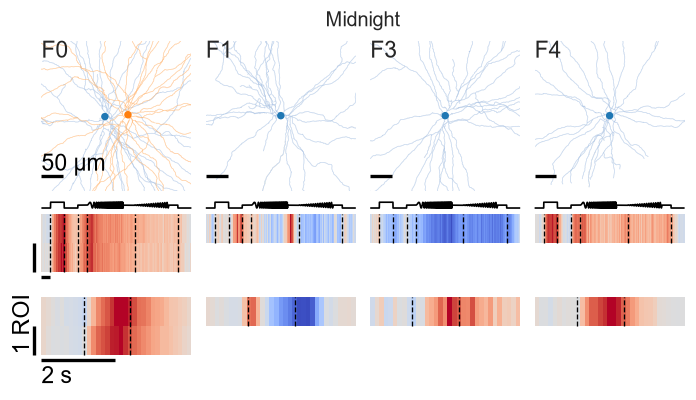

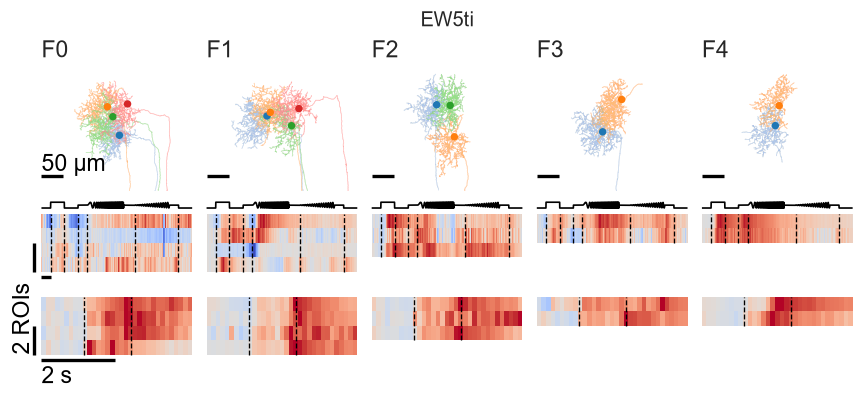

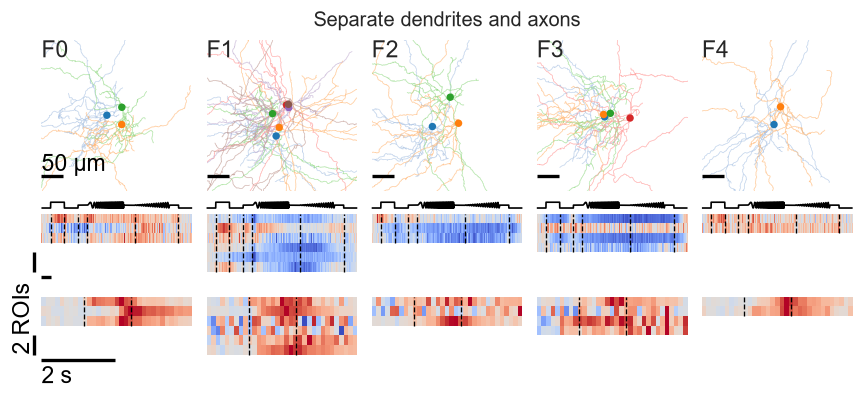

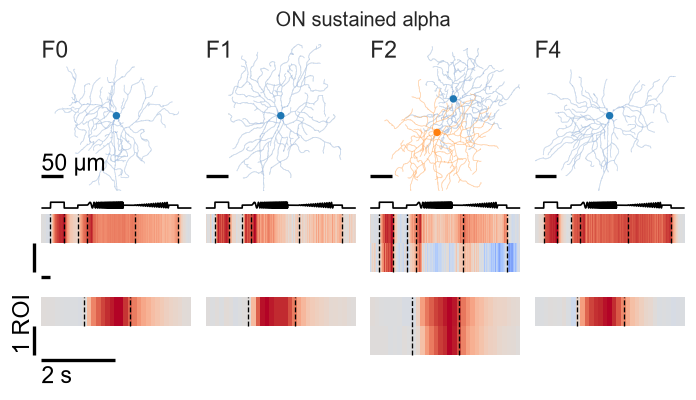

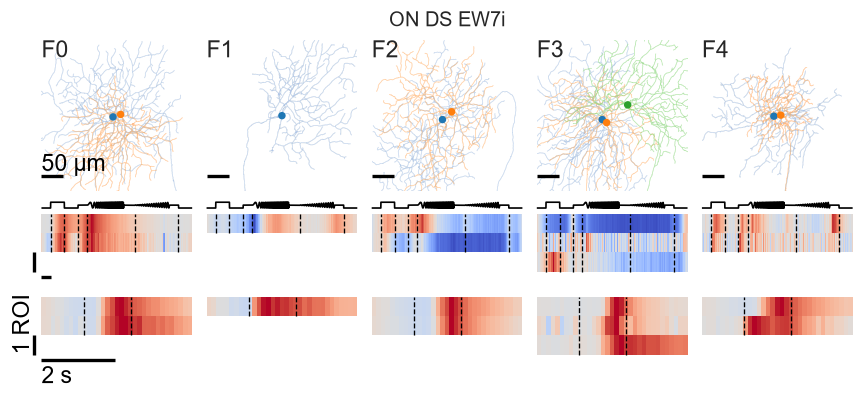

CPU times: total: 14.4 s
Wall time: 26 s


In [11]:
%%time
for cell_type in cell_types.index:
    fig, axs = plot_cell_type(df_sel, cell_type, chirp_stimulus)

    name = re.sub(r"[^A-Za-z0-9]+", "_", cell_type).strip("_")  # e.g. "m8:X" -> "m8_X"
    for ext in ("svg", "png"):
        fig.savefig(f"{fig_dir}/{name}.{ext}", bbox_inches="tight", dpi=300, facecolor="white")
    plt.show()

In [12]:
from watermark import watermark
print(watermark(packages="matplotlib,numpy,pandas,scipy,skeliner"))

matplotlib: 3.11.2
numpy     : 2.5.5
pandas    : 3.1.1
scipy     : 1.18.1
skeliner  : 0.3.1

